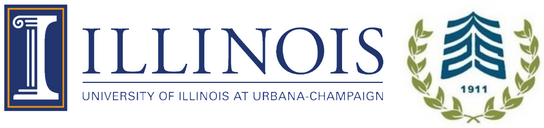

# pyDRMetrics

pyDRMetrics Provides a set of DR quality evaluation metrics.   
To install, `pip install cla`  
This document provides sample codes for how to use package API. The sample dataset can be downloaded from the github repo `https://github.com/zhangys11/pyDRMetrics` 

# Publication 
pyDRMetrics - A Python toolkit for dimensionality reduction quality assessment, Heliyon, Volume 7, Issue 2, 2021, e06199, ISSN 2405-8440, https://doi.org/10.1016/j.heliyon.2021.e06199. (https://www.sciencedirect.com/science/article/pii/S2405844021003042)

### Problems of high dimensionality

According to the theory of “curse of dimensionality”, as the number of dimensions increases, the amount of data needed to generalize a machine learning model grows exponentially. It also results in more storage space and longer model training time. 

For distance-baesd applications (e.g., clustering), "the concept of distance becomes less precise as the number of dimensions grows, since the distance between any two points in a given dataset converges (concentration effects)."
and
" Different clusters might be found in different subspaces, so a global filtering of attributes is not sufficient (local feature relevance problem)." 


### Reasons for dimensonality reduction: 

1. Reduce computational cost for learning and inference. 
2. Reduce the risk of overfitting. 
3. For data visualization.
4. For data interpretation.
5. Improve SNR. Denoising effect.

# 1. Load Data

Data source: Use of proteomic patterns in serum to identify ovarian cancer. Lancet.  

SELDI-TOF-MS

`plt.gray()`

In [1]:
import pandas as pd
data = pd.read_csv('./data/ovarian-cancer-nci-pbsii-data-no-header.csv', header = None)
print(data.head())

      0         1         2         3         4         5         6      \
0  0.494626  0.263735  0.321841  0.220934  0.297622  0.316458  0.154763   
1  0.258063  0.406593  0.321841  0.069771  0.333335  0.354432  0.321431   
2  0.537636  0.032966  0.321841  0.209307  0.404762  0.113927  0.369049   
3  0.000000  0.395605  0.310347  0.197673  0.404762  0.455701  0.416666   
4  0.526884  0.395605  0.367817  0.383719  0.488099  0.392405  0.238094   

      7         8         9      ...     15144     15145     15146     15147  \
0  0.223685  0.304346  0.241757  ...  0.467498  0.483622  0.449296  0.449296   
1  0.144740  0.260869  0.142853  ...  0.622356  0.631765  0.619718  0.619718   
2  0.223685  0.536231  0.131865  ...  0.032870  0.038462  0.035918  0.035918   
3  0.210527  0.420292  0.274723  ...  0.495252  0.497864  0.486621  0.486621   
4  0.500000  0.362316  0.274723  ...  0.245436  0.267096  0.251408  0.251408   

      15148     15149     15150     15151     15152     15153  
0  0

In [2]:
import numpy as np

cols = data.shape[1]

# convert from pandas dataframe to numpy matrices
X = np.array(data.iloc[:,1:-1]) # skip first and last cols
y = np.array(data.iloc[:,-1])

# X_names = list(data.columns.values[1:-1]) # -1 for removing the last column
labels = list(set(y))

In [3]:
# %load draw_averaged_waveform.py
import matplotlib.pyplot as plt
import numpy as np

def draw_averaged_waveform (X, X_names):

    plt.figure(figsize = (100,25))

    plt.scatter(X_names, np.mean(X,axis=0).tolist()) 

    cur_axes = plt.gca()
    cur_axes.axes.get_xaxis().set_visible(False) #.set_ticklabels([])
    cur_axes.axes.get_yaxis().set_visible(False) #.set_ticklabels([])       

    # plt.title(u'Averaged Spectrum\n', fontsize=50)
    plt.show()

## DR by PCA

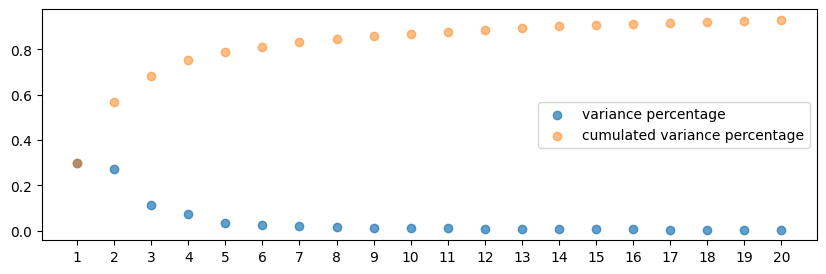

explained variance ratio: [0.29792598 0.27090529 0.1126371  0.07295763 0.03290289 0.02353424
 0.01988971 0.01540482 0.0116174  0.01111293 0.00971757 0.0083236
 0.00761821 0.00701775 0.0065432  0.00564775 0.00466537 0.00446773
 0.00387578 0.0037673 ]


In [4]:
from sklearn.decomposition import PCA
import matplotlib.ticker as mticker

K = 20

pca = PCA(n_components = K) # keep the first K components
pca.fit(X)
X_pca = pca.transform(X)

plt.figure(figsize=(10,3))
plt.scatter(list(range(1,K+1)), pca.explained_variance_ratio_, alpha=0.7, label='variance percentage')
plt.scatter(list(range(1,K+1)), pca.explained_variance_ratio_.cumsum(), alpha=0.5, label='cumulated variance percentage')
plt.gca().xaxis.set_major_locator(mticker.MultipleLocator(1))
plt.legend()
plt.show()

print('explained variance ratio:', pca.explained_variance_ratio_) 

With the "Elbow" method, choose k = 5. A turning point can be identified at around k =5. The explained variances (information) are less than 3% after k =5. The first 5 PCs hold 78.7% of the total information.

In [5]:
K = 5

pca = PCA(n_components = K) # keep the first K components
pca.fit(X)
Z = pca.transform(X)
Xr = pca.inverse_transform(Z)

# 2. Dimensionality Reduction Performance Measurement

In [6]:
from pyDRMetrics.pyDRMetrics import *
%matplotlib inline

In [7]:
drm = DRMetrics(X, Z, Xr) # this can be quite time consuming if your dataset is large (many samples and many features)

### 2.1 Reconstruction Error

Every DR method optimizes a different cost function, and it would be unfair to compare t-SNE and PCA by means of either recovered variance or KL-Divergence. One fair measure would be the reconstruction error, i.e., reconstructing the original data from a limited number of dimensions, but as discussed above not many methods provide forward and inverse mappings.


Use Frobenius Norm to compute MSE

$$
MSE = {{||X-Xr||}_F^2 \over {mn} }
$$

m,n is the dimension of A and A'. A-A' is the error matrix.

Relative Error

$$
R = { {{||X-Xr||}_F^2 \over {mn} } \over {{||X-0||}_F^2 \over {mn} } } = { {{||X-Xr||}_F^2  } \over {{||X||}_F^2  } }
$$

In [8]:
drm.mse, drm.rmse

(np.float64(0.006833716606761933), np.float64(0.03544851864403516))

### 2.2. Distance Matrix

Used to analyze whether distances are kept between samples after dimensionality reduction

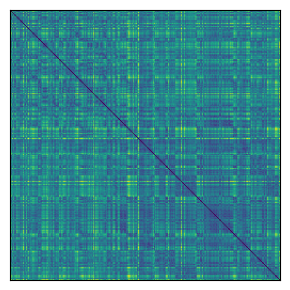

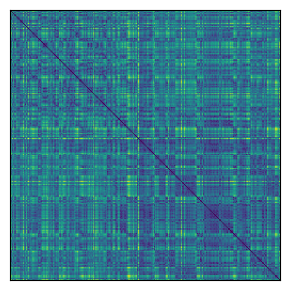

In [9]:
drm.plot_distance_matrix()

### 2.3 Residual Variance

Measure the correlation between the distance matrices in a high and low dimensional space.

 “residual variance” = 1 − $ r^2(D, D' )$,
where r is the Pearson or Spearman correlation and D, D' are the distances matrices.

obj.Vr returns the Pearson version (measures only linear correlation). obj.Vrs returns the Spearman version (also measures non-linear correlation).

In [10]:
drm.Vr, drm.Vrs

(np.float64(0.028547833617474927), np.float64(0.028487333201123066))

### 2.4 Parallel Comparison of Specific Samples

left column: original waveform		 right column: recovered waveform


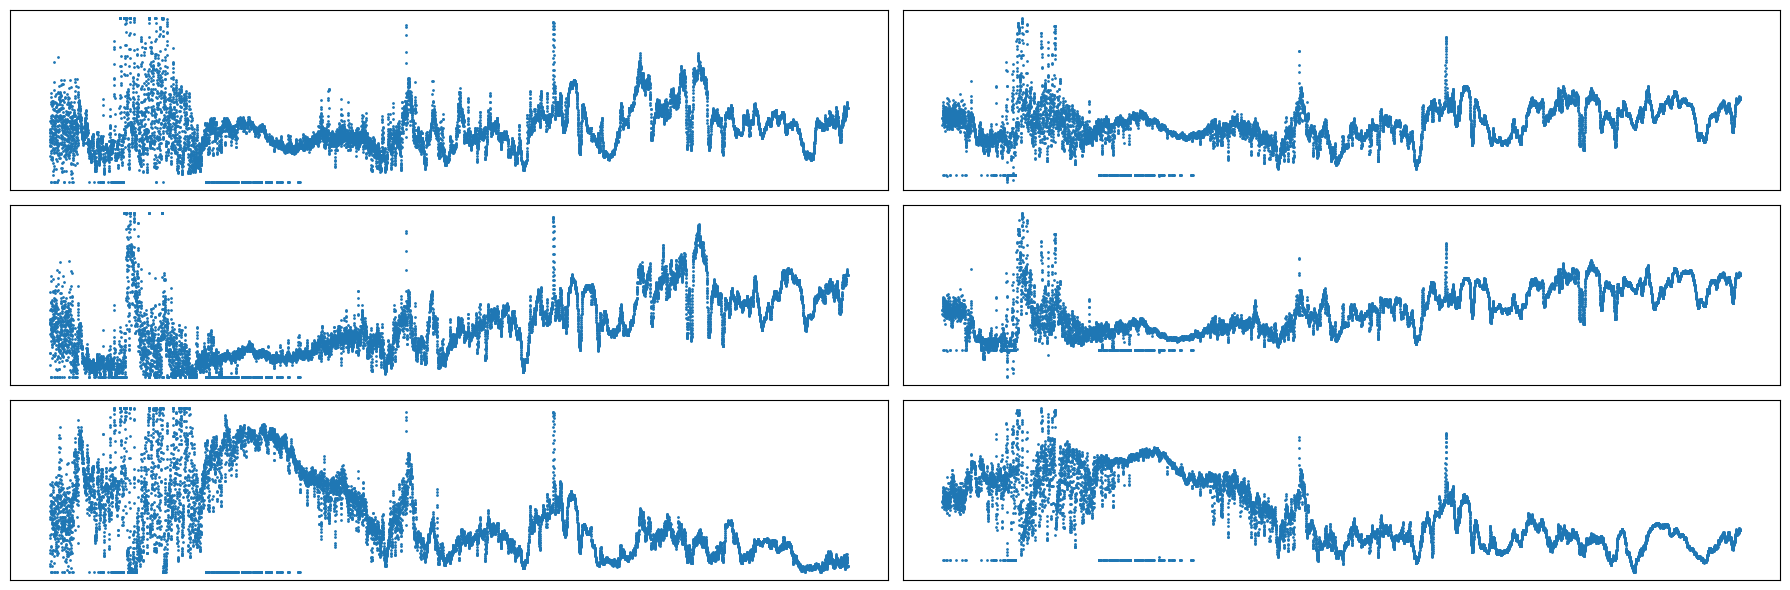

In [11]:
_ = visualize_sample_reconstruction(X, Xr, X_names=list(range(X.shape[1])), N = 3)

### 2.5 ranking matrix

rij = |{ k : dik < dij or (dik = dij and 1 ≤ k < j ≤ n) }|, |A| denotes the number of elements in a set A

本质上，distance matrix 和 ranking matrix 等价于核变换

In [12]:
rm = drm.R
m = len(drm.X)

# Ranking matrix properties
assert np.sum(rm) == m*m*(m-1)/2
assert np.max(rm) == m-1
assert np.min(rm) == 0

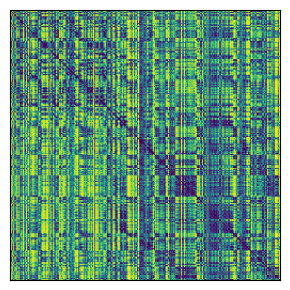

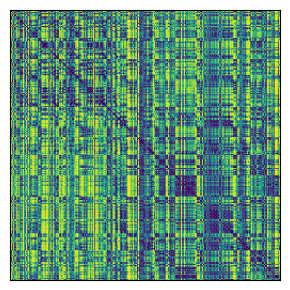

In [13]:
drm.plot_ranking_matrix()

### 2.6 定义co-ranking matrix

The co-ranking matrix Q then has elements: qkl = |{(i, j) : rˆij = k and rij = l }|

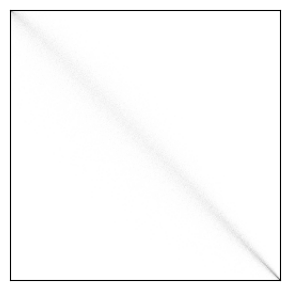

In [14]:
drm.plot_coranking_matrix()

In [15]:
Q = drm.Q
m = len(drm.X)
assert np.sum(Q) == m*m
assert np.isin(np.sum(Q, axis = 0), [m]).all()
assert np.isin(np.sum(Q, axis = 1), [m]).all()

co-ranking matrix is a 2d-histogram of the ranks. That is, qij is an integer which counts how many points of
distance rank j became rank i. In a perfect DR, this matrix will only have non-zero entries in the
diagonal.   
if most of the non-zero entries are in the lower triangle, then the DR collapsed far away points onto each other; if most of the non-zero entries are in the upper triangle, then the DR teared close points apart.

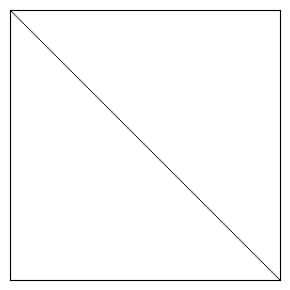

In [16]:
# an ideal Q is an diagnal matrix  
_ = visualize_matrix(np.eye(m)*m, cmap = 'gray_r')

### 2.6 Metrics derived from co-ranking matrix

Trustworthiness and continuity

$$
T(k) = 1 - \frac{1}{mk (m-k)} \sum^m_{i=1}
            \sum_{j \in \mathcal{LL}_{k}} \max(0, (r(i, j) - k))
$$

$$
C(k) = 1 - \frac{1}{mk (m-k)} \sum^m_{i=1}
            \sum_{j \in \mathcal{UR}_{k}} \max(0, (r(i, j) - k))
$$
    
    
    for k in range(m-1):
        Qs = Q[k:,:k]
        W = np.arange(Qs.shape[0]).reshape(-1, 1) # a column vector of weights. weight = rank error = actual_rank - k
        T[k] = 1-np.sum(Qs * W)/(k+1)/m/(m-1-k)  # 1 - normalized hard-k-intrusions. lower-left region. weighted by rank error (rank - k)
        Qs = Q[:k,k:]
        W = np.arange(Qs.shape[1]).reshape(1, -1) # a row vector of weights. weight = rank error = actual_rank - k
        C[k] = 1-np.sum(Qs * W)/(k+1)/m/(m-1-k)  # 1 - normalized hard-k-extrusions. upper-right region 

T AUC =  0.9957665477356022
C AUC =  0.9975479202140358


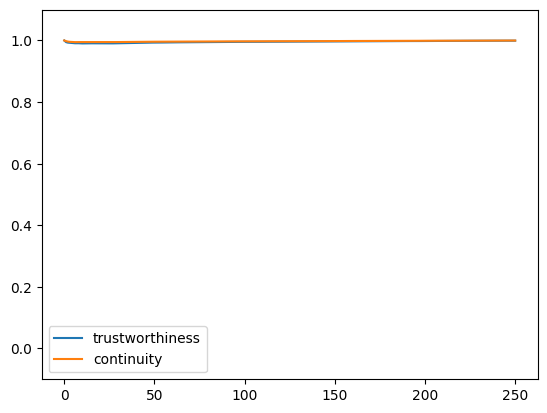

In [17]:
plt.plot(drm.T, label = 'trustworthiness')
plt.plot(drm.C, label = 'continuity')
plt.ylim(-0.1,1.1)
plt.legend()
print('T AUC = ', drm.AUC_T)
print('C AUC = ', drm.AUC_C)

$Q_{NN}(k) = {1 \over {kN}} \sum_{i=1}^k \sum_{j=1}^k q_{ij} $ 

$Q_{NN}(k) $ is the number of points that belong to the k-th nearest neighbors in both high- and low- dimensional space, normalized to give a maximum of 1.  
This quantity can be adjusted for random embeddings, giving the Local Continuity Meta Criterion. $ LCMC(k) = Q_{NN}(k) − k /(n − 1) $   

LCMC has a well defined maximum at $ k_{max} $. Two measures without parameters are defined:  
$ Q_{local} = { 1 \over k_{max}}  \sum_{k=1}^{k_{max}} Q_{NN}(k) $,   
$ Q_{global} = { 1 \over {n-k_{max}}}  \sum_{k=k_{max}}^{n-1} Q_{NN}(k) $,   
These measure the preservation of local and global distances respectively.

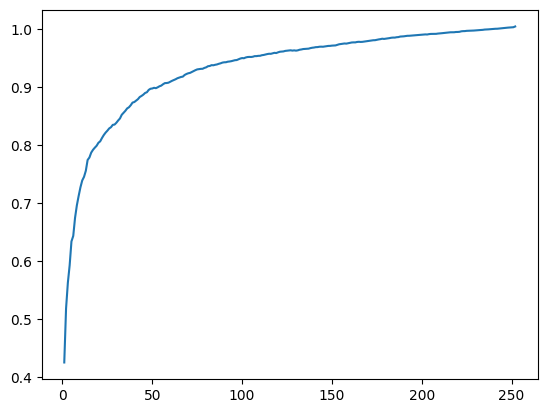

In [18]:
plt.plot(list(range(1, len(drm.QNN)+1)), drm.QNN)

In [19]:
drm.AUC

np.float64(0.9322314520275514)

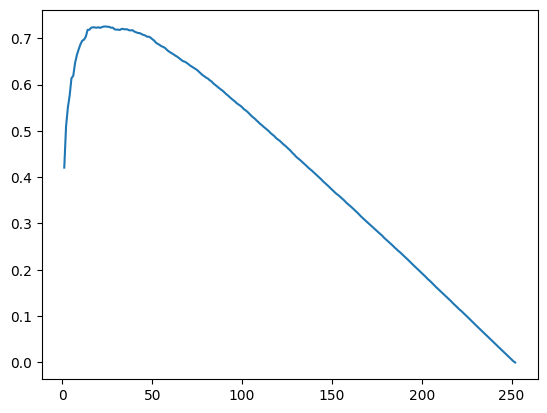

In [20]:
plt.plot(list(range(1, len(drm.LCMC)+1)), drm.LCMC)

In [21]:
drm.kmax # argmax(LCMC)

np.int64(23)

In [22]:
drm.Qlocal,drm.Qglobal

(np.float64(0.7166949983403357), np.float64(0.954116711563549))

## get_html() and get_json()

For use by web applications

--- Sample Reconstruction (X and Xr) ---
left column: original waveform		 right column: recovered waveform


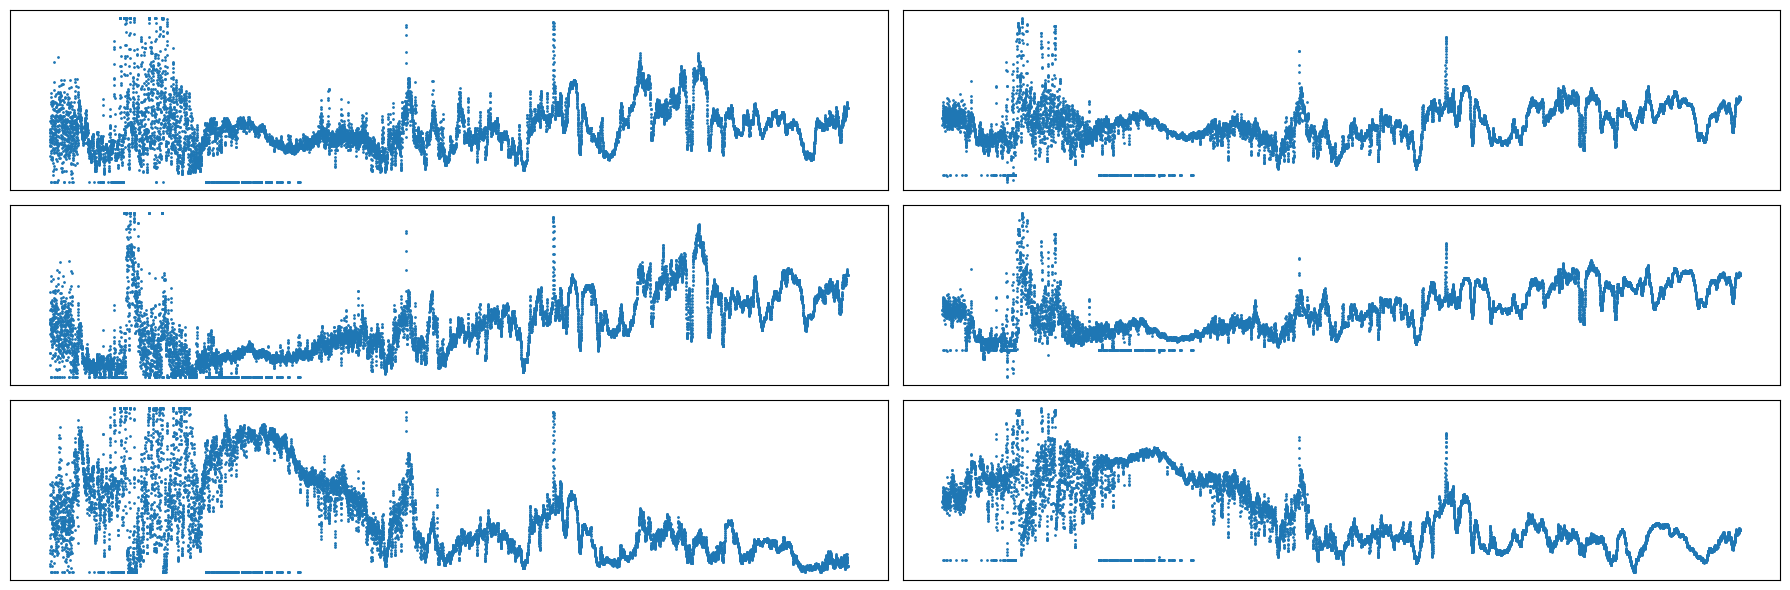

rMSE =  0.03544851864403516
--- Distance Matrices (D and Dz) ---


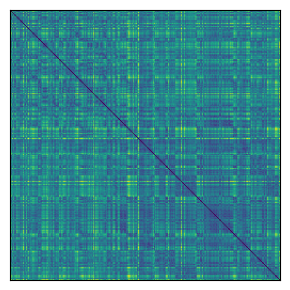

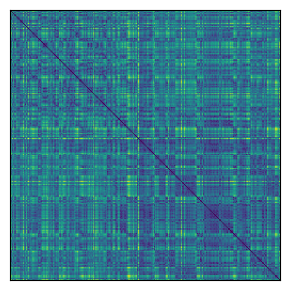

Residual Variance (using Pearson's r) =  0.028547833617474927
Residual Variance (using Spearman's r) =  0.028487333201123066
--- Ranking Matrices (R and Rz) ---


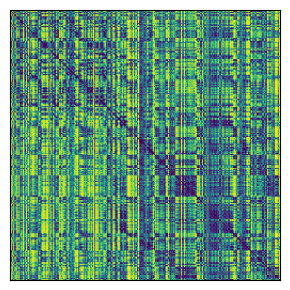

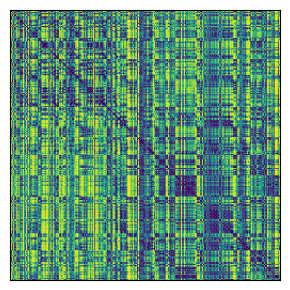

--- Co-ranking Matrix (Q) ---


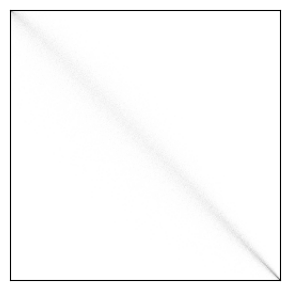

--- Trustworthiness T(k) and Continuity C(k) ---


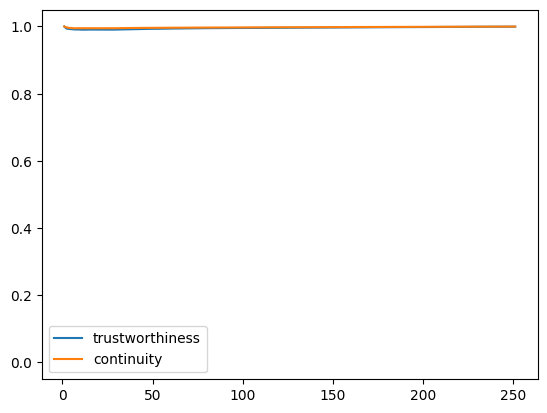

AUC of T =  0.9957665477356022
AUC of C =  0.9975479202140358
--- QNN(k) Curve ---


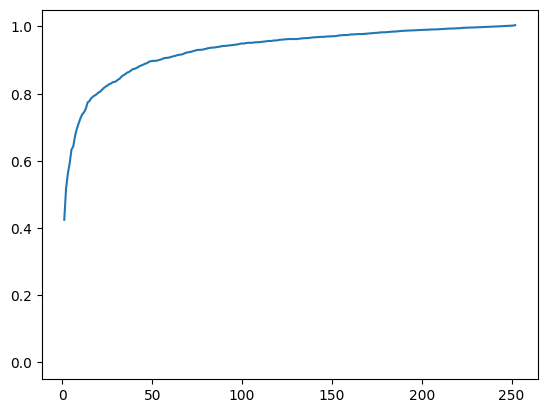

AUC of QNN =  0.9322314520275514
--- LCMC(k) Curve ---


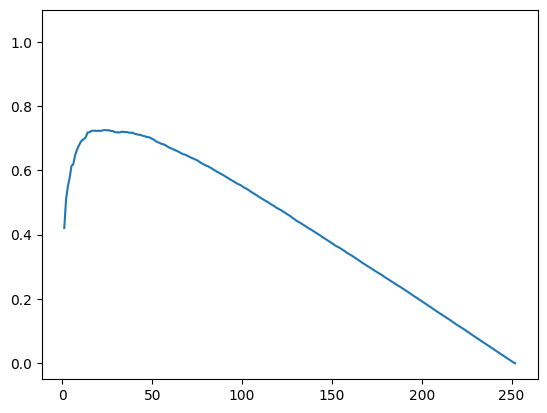

kmax (0-based index) =  23
Qlocal =  0.7166949983403357
Qglobal =  0.954116711563549


In [23]:
from IPython.display import display, HTML
# display(HTML(drm.get_html()))
drm.report()

In [24]:
s = drm.get_json()
dic = json.loads(s)
dic.keys()

dict_keys(['mse', 'ms', 'rmse', 'Vr', 'Vrs', 'AUC', 'kmax', 'Qlocal', 'Qglobal', 'AUC_T', 'AUC_C'])

# Dynamic Properties

Let k in the range [1,21] and check PCA's metrics

In [25]:
from sklearn.decomposition import PCA

drms = []
rmses = []
AUCs = []
Qlocals = []
Qglobals = []
Vrs = []

for k in range(1,21):

    pca = PCA(n_components = k) # keep the first k components
    pca.fit(X)
    Z = pca.transform(X)
    # plotComponents3D(Z, y, labels)
    Xr = pca.inverse_transform(Z)

    drm = DRMetrics(X, Z, Xr)
    drms.append(drm)
    
    rmses.append(drm.rmse)
    Vrs.append(drm.Vr)
    AUCs.append(drm.AUC)
    Qlocals.append(drm.Qlocal)
    Qglobals.append(drm.Qglobal)

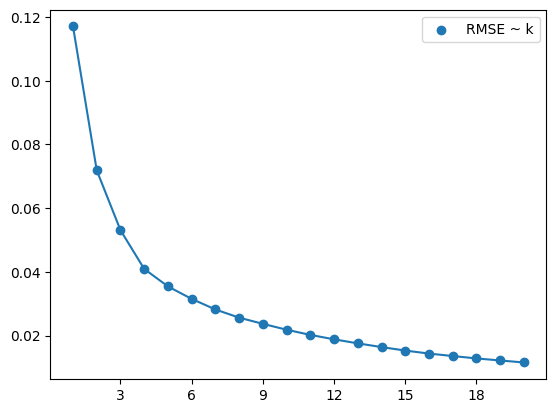

In [26]:
from matplotlib.ticker import MaxNLocator
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.plot(list(range(1,21)),  rmses)
plt.scatter(list(range(1,21)),  rmses, label = 'RMSE ~ k')
plt.legend()

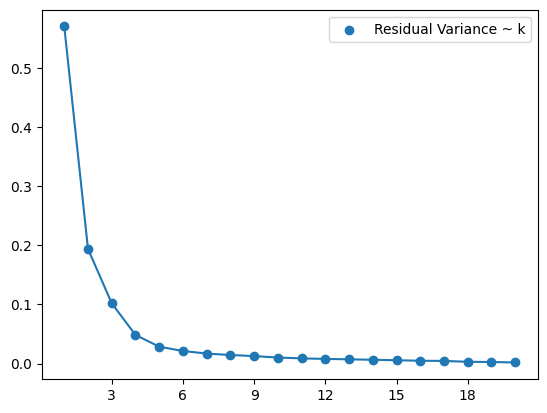

In [27]:
from matplotlib.ticker import MaxNLocator
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.plot(list(range(1,21)),  Vrs)
plt.scatter(list(range(1,21)),  Vrs, label = 'Residual Variance ~ k')
plt.legend()

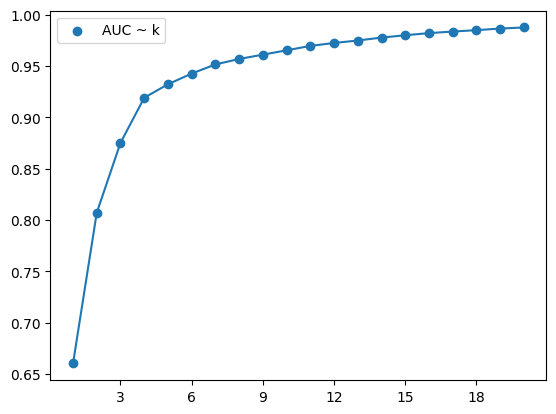

In [28]:
from matplotlib.ticker import MaxNLocator
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.plot(list(range(1,21)),AUCs)
plt.scatter(list(range(1,21)),  AUCs, label = 'AUC ~ k')
plt.legend()

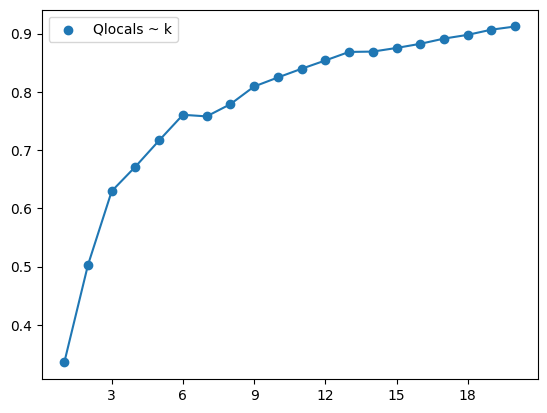

In [29]:
from matplotlib.ticker import MaxNLocator
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.plot(list(range(1,21)),Qlocals)
plt.scatter(list(range(1,21)),  Qlocals, label = 'Qlocals ~ k')
plt.legend()

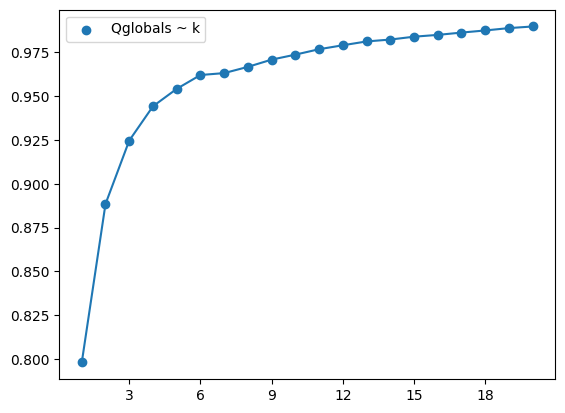

In [30]:
from matplotlib.ticker import MaxNLocator
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.plot(list(range(1,21)),Qglobals)
plt.scatter(list(range(1,21)),  Qglobals, label = 'Qglobals ~ k')
plt.legend()

## Case Study 2: Raman spectra

### Test PCA and VQ

--- Sample Reconstruction (X and Xr) ---
left column: original waveform		 right column: recovered waveform


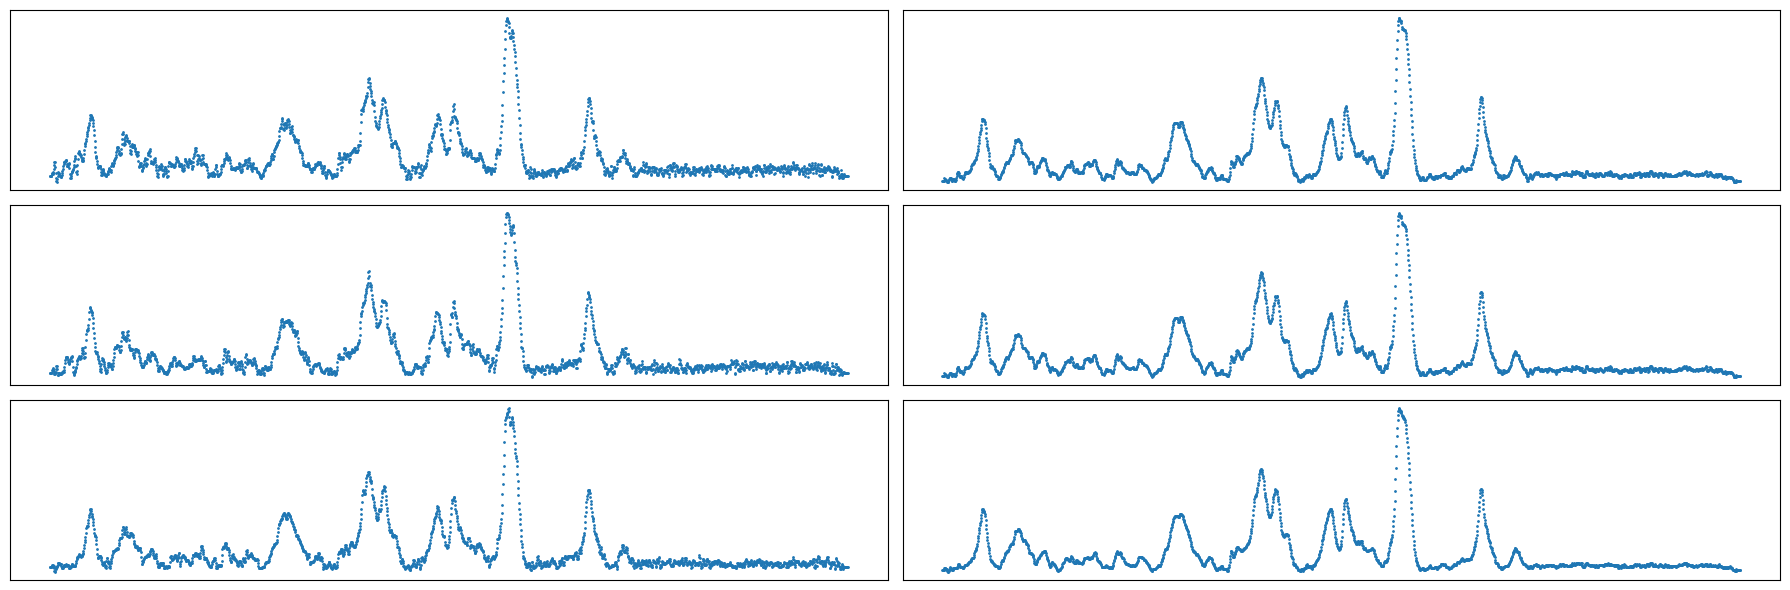

rMSE =  0.010637683165950571
--- Distance Matrices (D and Dz) ---


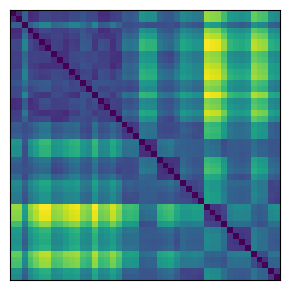

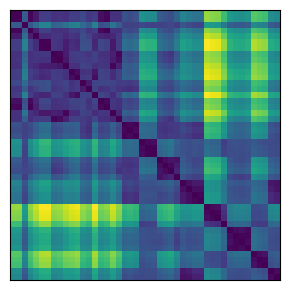

Residual Variance (using Pearson's r) =  0.011266375463165001
Residual Variance (using Spearman's r) =  0.008193266039717928
--- Ranking Matrices (R and Rz) ---


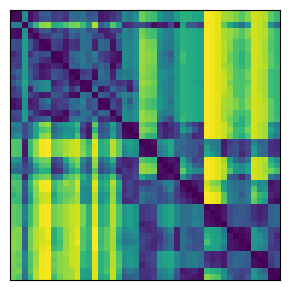

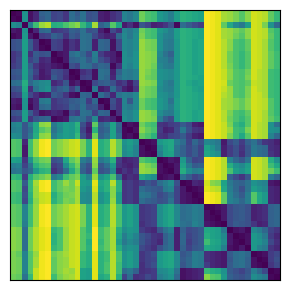

--- Co-ranking Matrix (Q) ---


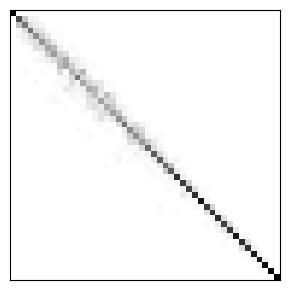

--- Trustworthiness T(k) and Continuity C(k) ---


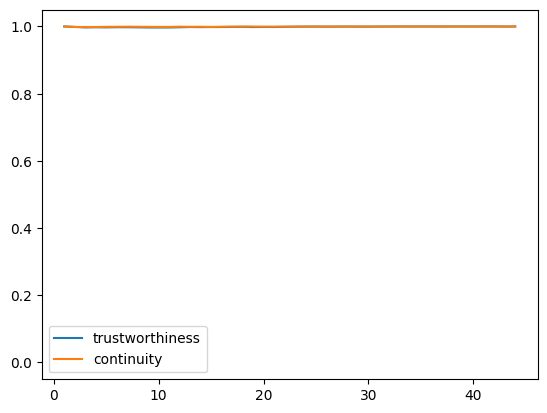

AUC of T =  0.9989085475189007
AUC of C =  0.9995364059806525
--- QNN(k) Curve ---


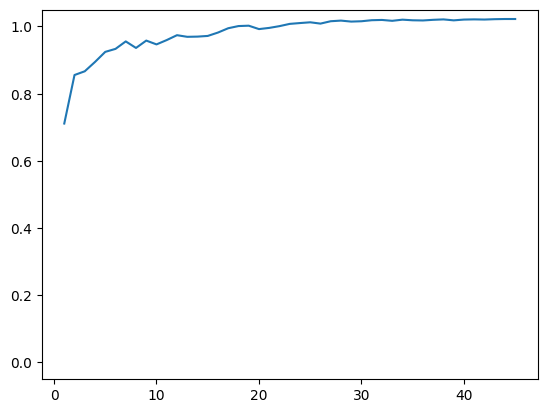

AUC of QNN =  0.9821554030923509
--- LCMC(k) Curve ---


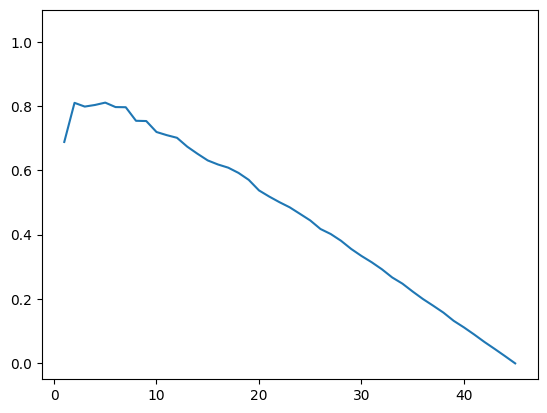

kmax (0-based index) =  4
Qlocal =  0.8504444444444446
Qglobal =  0.9961748284788946


In [31]:
from pyDRMetrics import *

drm = DRMetrics.test('./data/raman.csv', 3, dr = 'PCA')
drm.report()

In [32]:
np.savetxt('./data/raman_z.csv',drm.Z,fmt='%f',delimiter=',')
np.savetxt('./data/raman_xr.csv',drm.Xr,fmt='%f',delimiter=',')

--- Sample Reconstruction (X and Xr) ---
left column: original waveform		 right column: recovered waveform


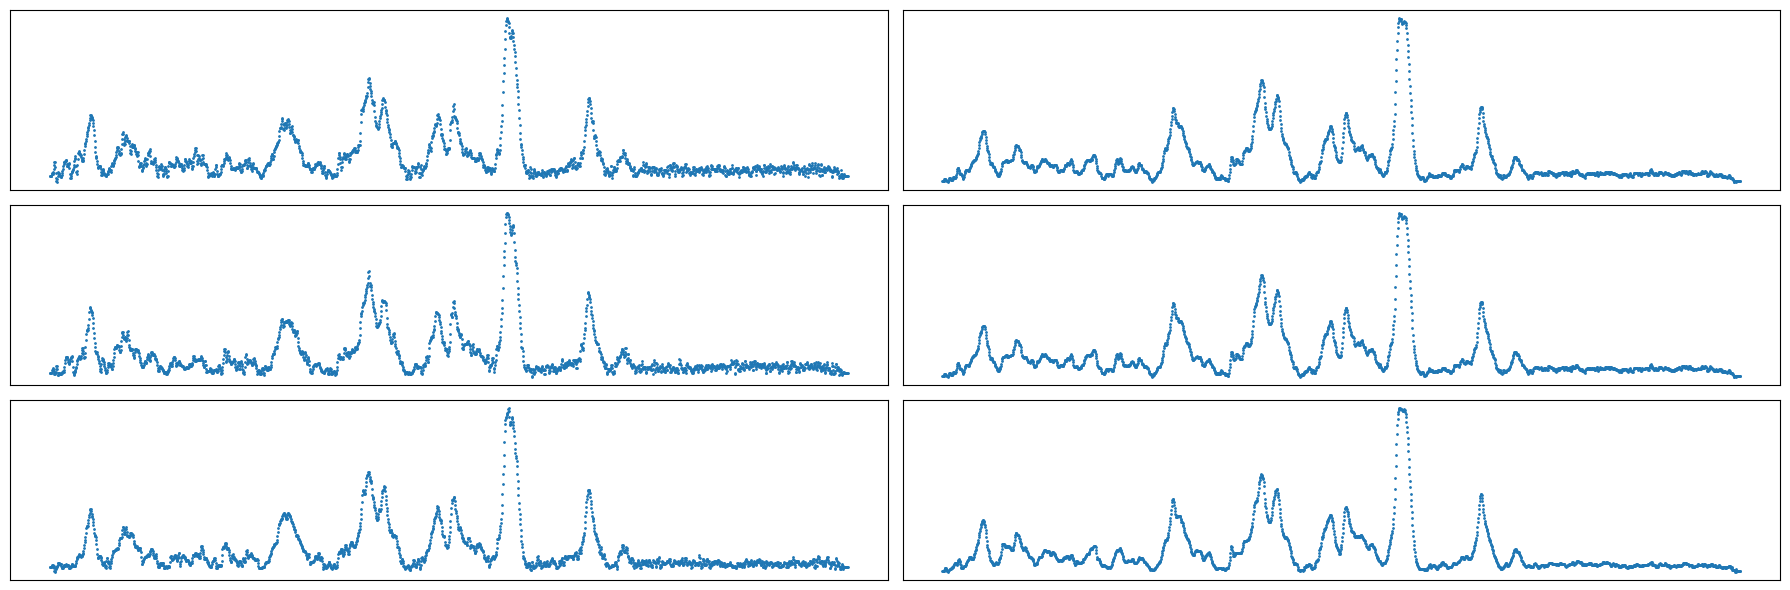

rMSE =  0.026951703948641513
--- Distance Matrices (D and Dz) ---


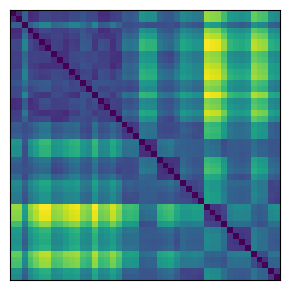

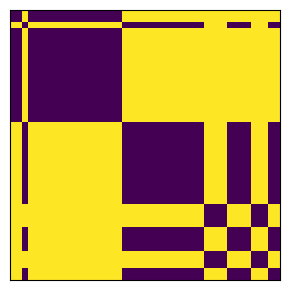

Residual Variance (using Pearson's r) =  0.5395973900914559
Residual Variance (using Spearman's r) =  0.4335242825152841
--- Ranking Matrices (R and Rz) ---


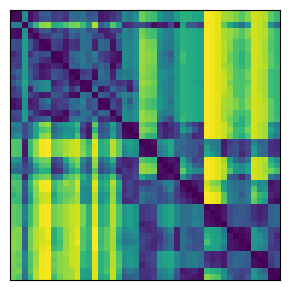

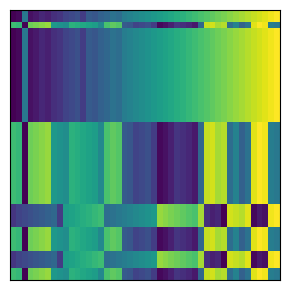

--- Co-ranking Matrix (Q) ---


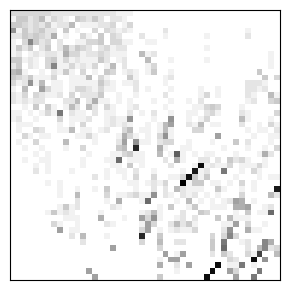

--- Trustworthiness T(k) and Continuity C(k) ---


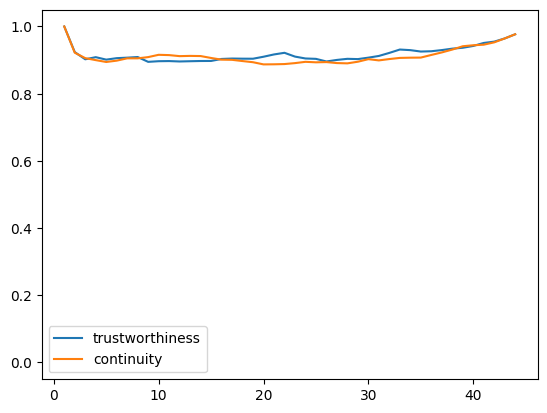

AUC of T =  0.9173274266609269
AUC of C =  0.9122097725488733
--- QNN(k) Curve ---


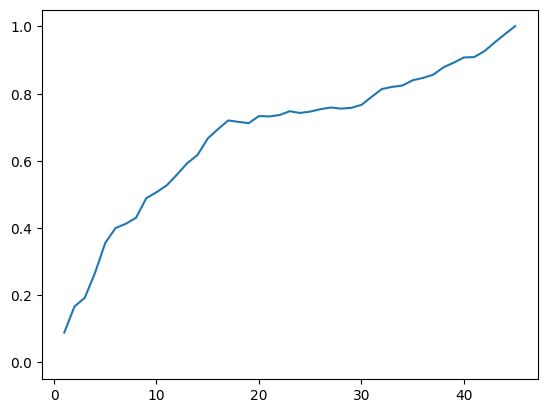

AUC of QNN =  0.6796611437506092
--- LCMC(k) Curve ---


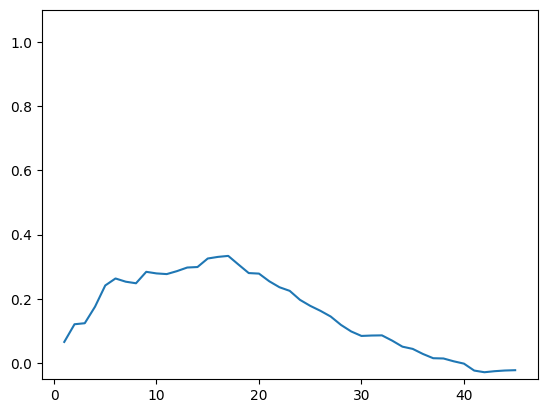

kmax (0-based index) =  16
Qlocal =  0.4522180670796588
Qglobal =  0.8077256468575259


In [33]:
from pyDRMetrics import *

drm = DRMetrics.test('./data/raman.csv', 3, dr = 'VQ') # VQ or Clustering is a special form of dimensionality reduction
drm.report()

## Case Study 3: Handwritten digits data

### Test NMF and MDS

--- Sample Reconstruction (X and Xr) ---
left column: original waveform		 right column: recovered waveform


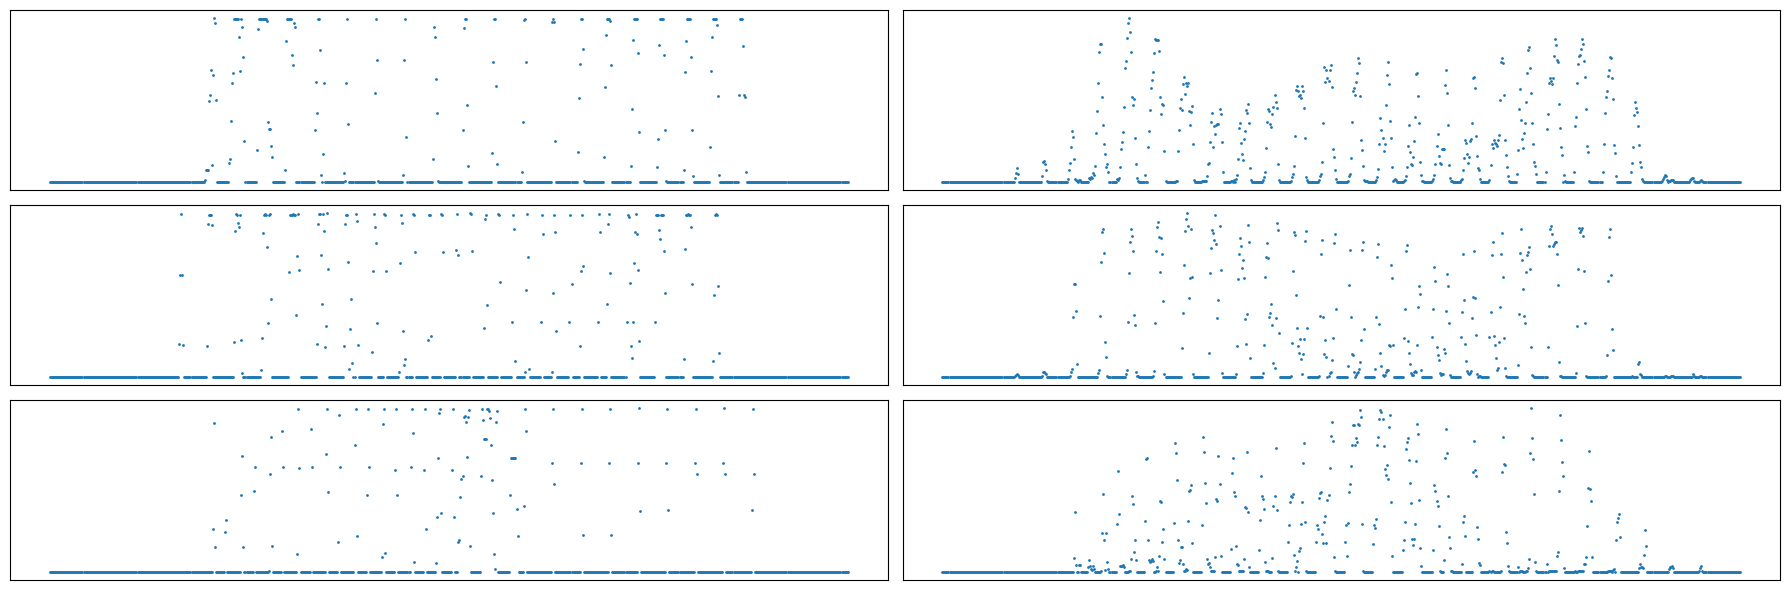

rMSE =  0.2715335362192076
--- Distance Matrices (D and Dz) ---


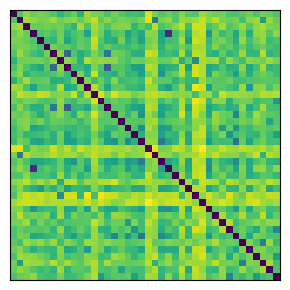

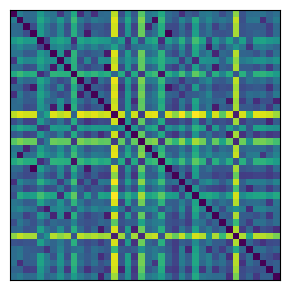

Residual Variance (using Pearson's r) =  0.8646538376770079
Residual Variance (using Spearman's r) =  0.9019110954706965
--- Ranking Matrices (R and Rz) ---


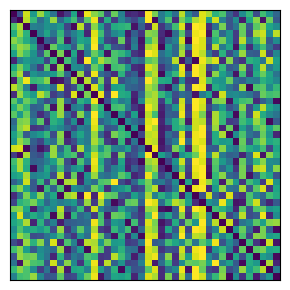

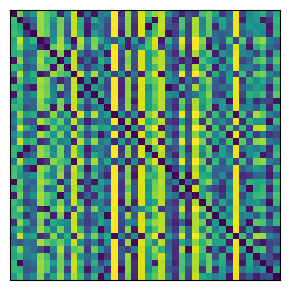

--- Co-ranking Matrix (Q) ---


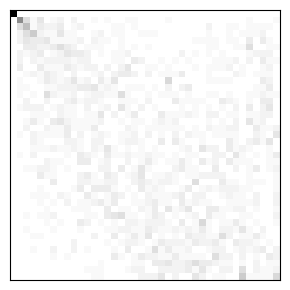

--- Trustworthiness T(k) and Continuity C(k) ---


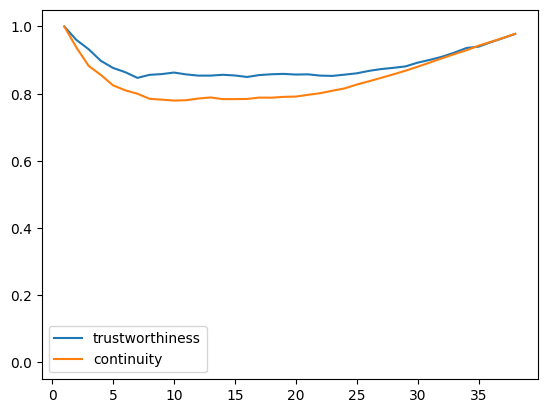

AUC of T =  0.8864869428077367
AUC of C =  0.8459947699340266
--- QNN(k) Curve ---


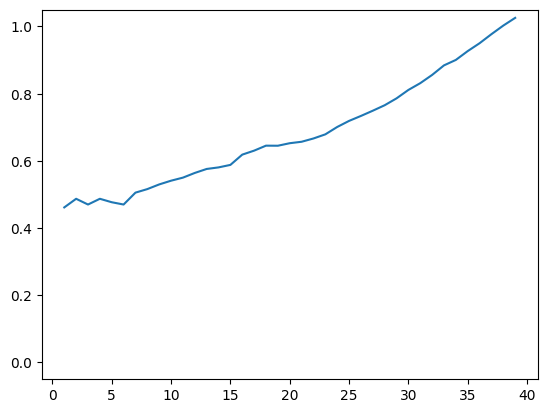

AUC of QNN =  0.6825215133123862
--- LCMC(k) Curve ---


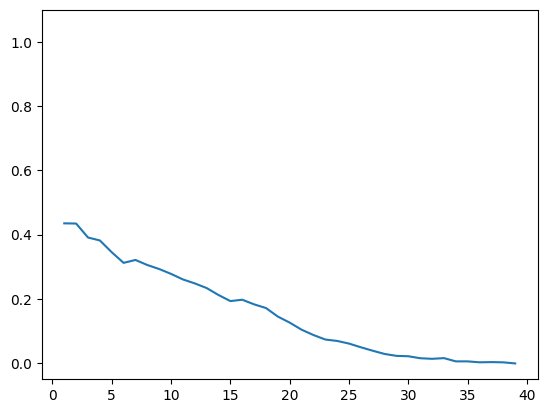

kmax (0-based index) =  0
Qlocal =  0.46153846153846156
Qglobal =  0.6734920524616325


In [34]:
from pyDRMetrics import *

drm = DRMetrics.test('./data/digits.csv', 8, dr = 'NMF')
drm.report()

### 本组数据集为图片，以下进行reshape操作进行可视化，对比原始与复原数据

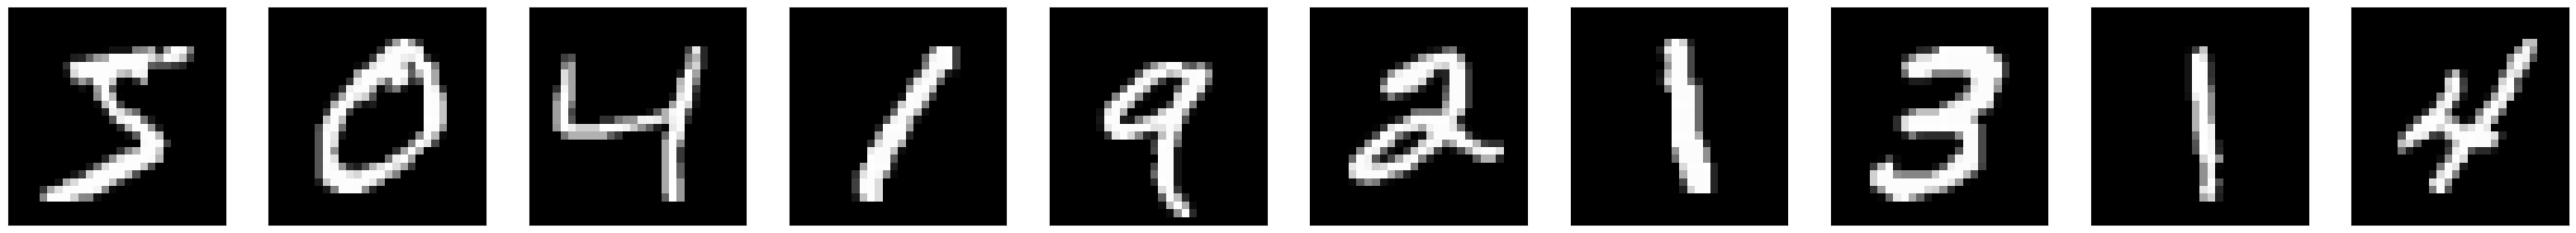

In [35]:
import pandas as pd

# Each data is actually a 28x28, flattened into a 784 vector.
# We can restore to its original shape to visuzlize.

N = 10        
plt.figure(figsize = (4*N,5))
for i in range(N):
    x = drm.X[i]
    ax = plt.subplot(1, N, i+1)
    plt.imshow(x.reshape((28,28)), cmap='gray')
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

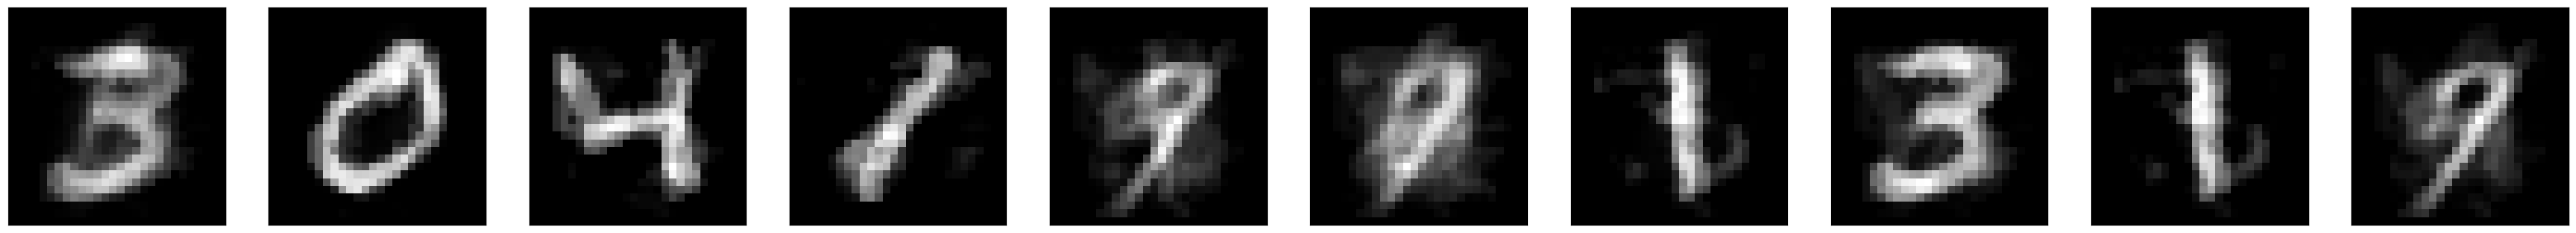

In [36]:
N = 10        
plt.figure(figsize = (4*N,5))
for i in range(N):
    x = drm.Xr[i]
    ax = plt.subplot(1, N, i+1)
    plt.imshow(x.reshape((28,28)), cmap='gray')
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

--- Distance Matrices (D and Dz) ---


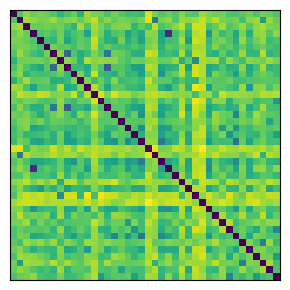

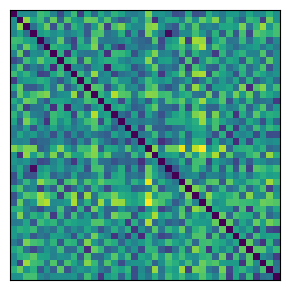

Residual Variance (using Pearson's r) =  0.4178779674171744
Residual Variance (using Spearman's r) =  0.4455077389141521
--- Ranking Matrices (R and Rz) ---


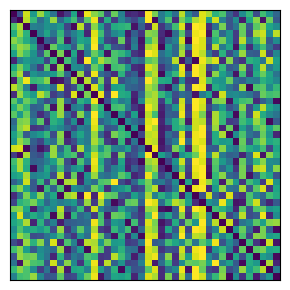

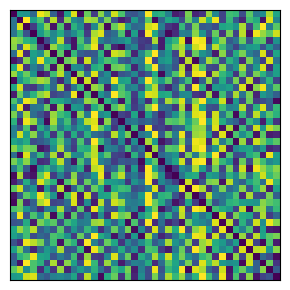

--- Co-ranking Matrix (Q) ---


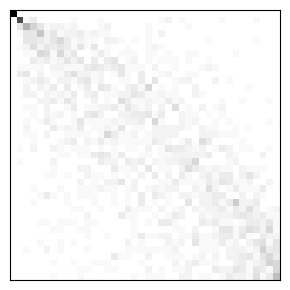

--- Trustworthiness T(k) and Continuity C(k) ---


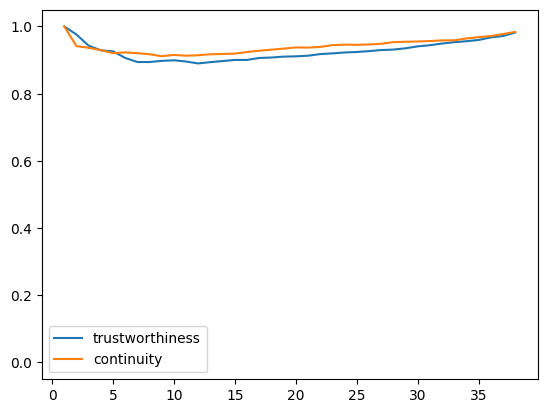

AUC of T =  0.9269219248933315
AUC of C =  0.9411022501574597
--- QNN(k) Curve ---


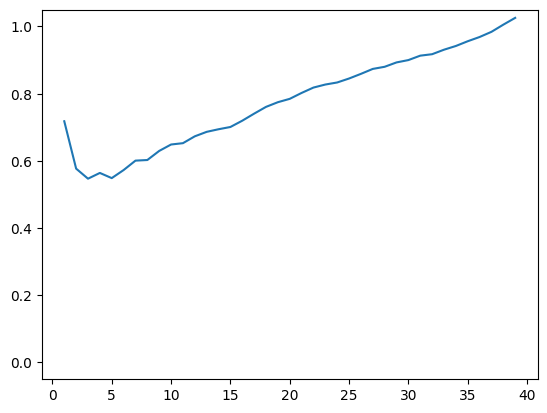

AUC of QNN =  0.7787475448517619
--- LCMC(k) Curve ---


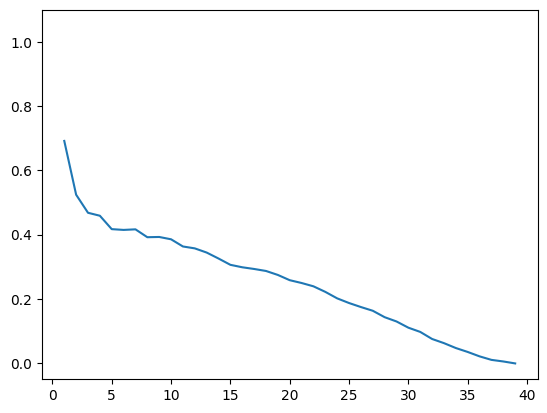

kmax (0-based index) =  0
Qlocal =  0.717948717948718
Qglobal =  0.7722503479888866


In [38]:
from pyDRMetrics import *

drm = DRMetrics.test('./data/digits.csv', 3, dr = 'MDS')
drm.report()

# Appendix A: Built-in algorithms

    Algorithm 	Description 	Implementation
    PCA 	Principal Component Analysis 	sklearn.decomposition.PCA
    NMF 	Non-negative Matrix Factorization 	sklearn.decomposition.NMF
    RP 	Random Projection 	sklearn.random_projection.GaussianRandomProjection
    VQ 	Vector Quantization (by K-means) 	sklearn.cluster.KMeans
    MDS 	Multidimensional scaling 	sklearn.manifold.MDS
    t-SNE 	t-distributed Stochastic Neighbor Embedding 	sklearn.manifold.TSNE
    Identity 	A "perfect" DR 	X = Z = Xr 

# Appendix B: pyDRMetrics main APIs

   ## class DRMetrics(builtins.object)
   ### Properties / Fields
    X	Data before DR. m-by-n matrix. m is the sample size. n is the dimension/feature number.
    Z	Data after DR. m-by-k matrix. Typically, k << n
    Xr	Reconstructed Data. m-by-n matrix. Optional parameter. If a DR algorithm has no inverse transform. Pass None.
    D	Distance matrix of X
    Dz	Distance matrix of Z
    Vr	The residual variance between D and Dz. The default version uses Pearson’s r to calculate the residual variance. Use Vrs for the Spearman’s r version.
    mse	Reconstruction error. MSE of X and Xr
    rmse	Relative reconstruction error. Relative MSE of X and Xr
    R	Ranking matrix of X
    Rz	Ranking matrix of Z
    Q	Co-ranking matrix between R and Rz
    T	Trustworthiness. An array. There is also a single-valued AUC_T that measures the area under the T(trustworthiness) curve.
    C	Continuity. An array. There is also a single-valued AUC_C that measures the area under the C(continuity) curve.
    QNN	Co-k-nearest neighbor size. An array.
    AUC	The area under the QNN curve. 
    LCMC	Local Continuity Meta Criterion. An array.
    Qlocal	Local property metric
    Qglobal	Global property metric
   ### Member Methods
    __init__(self, X, Z, Xr=None)	Constructor. X is the original data. Z is the data after DR. Xr is the reconstructed data.
    test(cls, csv, k = 3, dr = 'PCA')	A constructor overload that facilitates testing common DR algorithms. csv is the data file. dr is used to specify the algorithm, e.g. “PCA”, “NMF”, “RP”, “TSNE”, etc.
    plot_coranking_matrix(self)	Visualize the co-ranking matrix between R and Rz as heatmaps.
    plot_distance_matrix(self)	Visualize the distance matrices before and after DR as heatmaps, i.e., D and Dz.
    plot_ranking_matrix(self)	Visualize the ranking matrices before and after DR as heatmaps, i.e., R and Rz.
    visualize_reconstruction(self)	Plot the original data and the reconstruction data side by side. Show 3 random samples.
    report(self)	Print out a summary report, with inline plots.
    get_json(self)	Generate a JSON-format dictionary object containing all DR quality metrics. Only numeric metrics are returned.
    get_html(self)	Generate an HTML segment that can be embedded in web pages. Plotted images are embedded as base64 strings to avoid referencing external files.
   ### Sample Code
    from pyDRMetrics import *
    from sklearn.decomposition import PCA
    %matplotlib inline

    K = 3
    pca = PCA(n_components = K) # keep the first K components
    pca.fit(X)
    Z = pca.transform(X)
    plotComponents3D(Z, y, labels)
    Xr = pca.inverse_transform(Z)
    print('explained variance ratio:', pca.explained_variance_ratio_[0:5])

    drm = DRMetrics(X, Z, Xr) # construct a DRMetrics object
    print("Qlocal = ", drm.Qlocal) # get Qlocal
    drm.report() # print out the summary

    from IPython.display import display, HTML
    display(HTML(drm.get_html())) # render the returned html string. You can embed this HTML segment in a web page.


# Appendix C: A web GUI tool based on pyDRMetrics

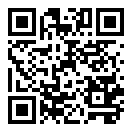